In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

sns.set_theme(style="whitegrid")

In [2]:
DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
FIGURE_DIR = Path("../reports/figures")
RESULT_DIR = Path("../reports/results")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Directories configured successfully!")

Directories configured successfully!


In [3]:
X_val = pd.read_csv(DATA_DIR / "X_val.csv")

y_val = pd.read_csv(
    DATA_DIR / "y_val.csv"
)["label"]

print("Validation Features:", X_val.shape)
print("Validation Target:", y_val.shape)

print("\nClass Distribution:")
print(y_val.value_counts())

Validation Features: (35067, 42)
Validation Target: (35067,)

Class Distribution:
label
1    23867
0    11200
Name: count, dtype: int64


In [4]:
models = {
    "Logistic Regression": joblib.load(
        MODEL_DIR / "logistic_regression.pkl"
    ),

    "Decision Tree": joblib.load(
        MODEL_DIR / "decision_tree.pkl"
    ),

    "Random Forest": joblib.load(
        MODEL_DIR / "random_forest.pkl"
    )
}

for name in models:
    print(f"{name} loaded successfully!")

Logistic Regression loaded successfully!
Decision Tree loaded successfully!
Random Forest loaded successfully!


In [5]:
def evaluate_model(name, model, X, y):

    start_time = time.perf_counter()

    y_pred = model.predict(X)

    prediction_time = time.perf_counter() - start_time

    y_prob = model.predict_proba(X)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y, y_pred, labels=[0, 1]
    ).ravel()

    results = {
        "Model": name,

        "Accuracy": accuracy_score(y, y_pred),

        "Precision": precision_score(
            y, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y, y_pred, zero_division=0
        ),

        "F1 Score": f1_score(
            y, y_pred, zero_division=0
        ),

        "ROC AUC": roc_auc_score(y, y_prob),

        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp,

        "False Negative Rate": fn / (fn + tp),

        "False Positive Rate": fp / (fp + tn),

        "Prediction Time (Seconds)": prediction_time
    }

    return results, y_pred, y_prob

In [6]:
evaluation_results = []

predictions = {}
probabilities = {}

for name, model in models.items():

    print(f"Evaluating {name}...")

    result, y_pred, y_prob = evaluate_model(
        name,
        model,
        X_val,
        y_val
    )

    evaluation_results.append(result)

    predictions[name] = y_pred

    probabilities[name] = y_prob

    print(f"{name} evaluation completed!\n")

print("All models evaluated successfully!")

Evaluating Logistic Regression...
Logistic Regression evaluation completed!

Evaluating Decision Tree...
Decision Tree evaluation completed!

Evaluating Random Forest...
Random Forest evaluation completed!

All models evaluated successfully!


In [7]:
performance_df = pd.DataFrame(
    evaluation_results
)

performance_df = performance_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

metric_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

display(
    performance_df[metric_columns].round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.9537,0.9572,0.9757,0.9663,0.9928
1,Decision Tree,0.9428,0.9594,0.9565,0.9579,0.9365
2,Logistic Regression,0.9352,0.9219,0.9886,0.9541,0.9845


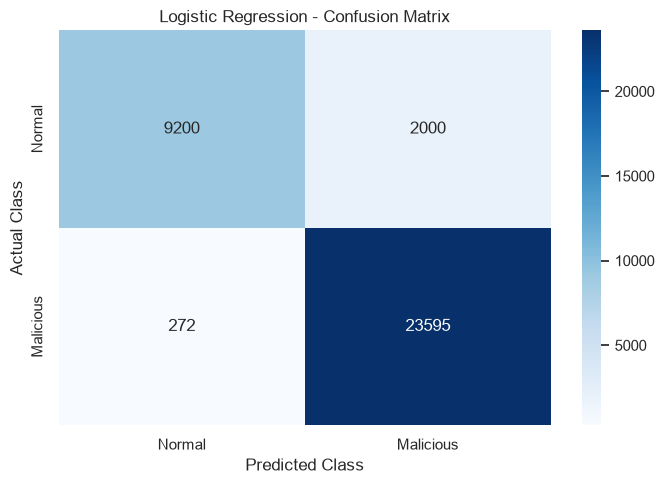

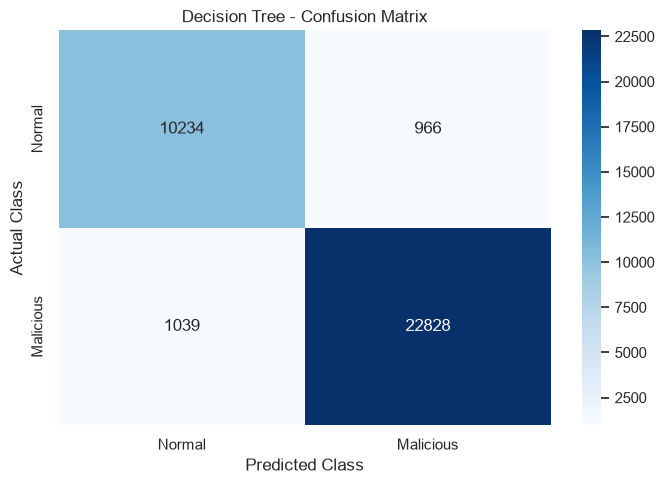

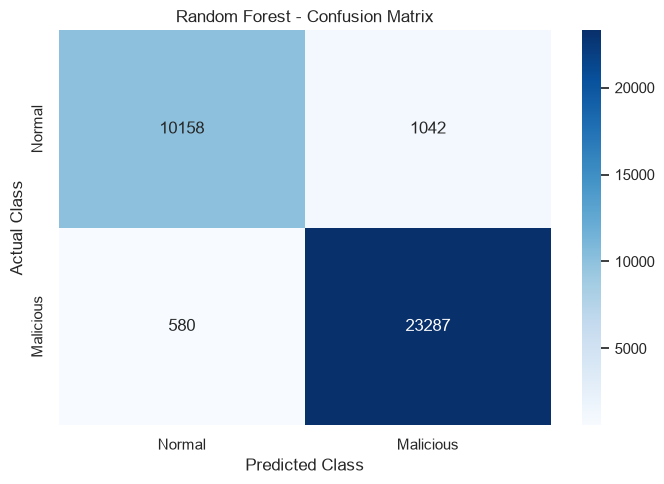

In [8]:
model_filenames = {
    "Logistic Regression": "logistic_regression",
    "Decision Tree": "decision_tree",
    "Random Forest": "random_forest"
}

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Malicious"],
        yticklabels=["Normal", "Malicious"]
    )

    plt.title(f"{name} - Confusion Matrix")

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"{model_filenames[name]}_cm.png",
        dpi=300
    )

    plt.show()

In [9]:
classification_reports = []

for name, y_pred in predictions.items():

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_val,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Normal Traffic",
            "Malicious Traffic"
        ],
        zero_division=0
    ))

    report = classification_report(
        y_val,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Normal Traffic",
            "Malicious Traffic"
        ],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    report_df["Model"] = name

    classification_reports.append(report_df)

Logistic Regression
                   precision    recall  f1-score   support

   Normal Traffic       0.97      0.82      0.89     11200
Malicious Traffic       0.92      0.99      0.95     23867

         accuracy                           0.94     35067
        macro avg       0.95      0.91      0.92     35067
     weighted avg       0.94      0.94      0.93     35067

Decision Tree
                   precision    recall  f1-score   support

   Normal Traffic       0.91      0.91      0.91     11200
Malicious Traffic       0.96      0.96      0.96     23867

         accuracy                           0.94     35067
        macro avg       0.93      0.94      0.93     35067
     weighted avg       0.94      0.94      0.94     35067

Random Forest
                   precision    recall  f1-score   support

   Normal Traffic       0.95      0.91      0.93     11200
Malicious Traffic       0.96      0.98      0.97     23867

         accuracy                           0.95     35067


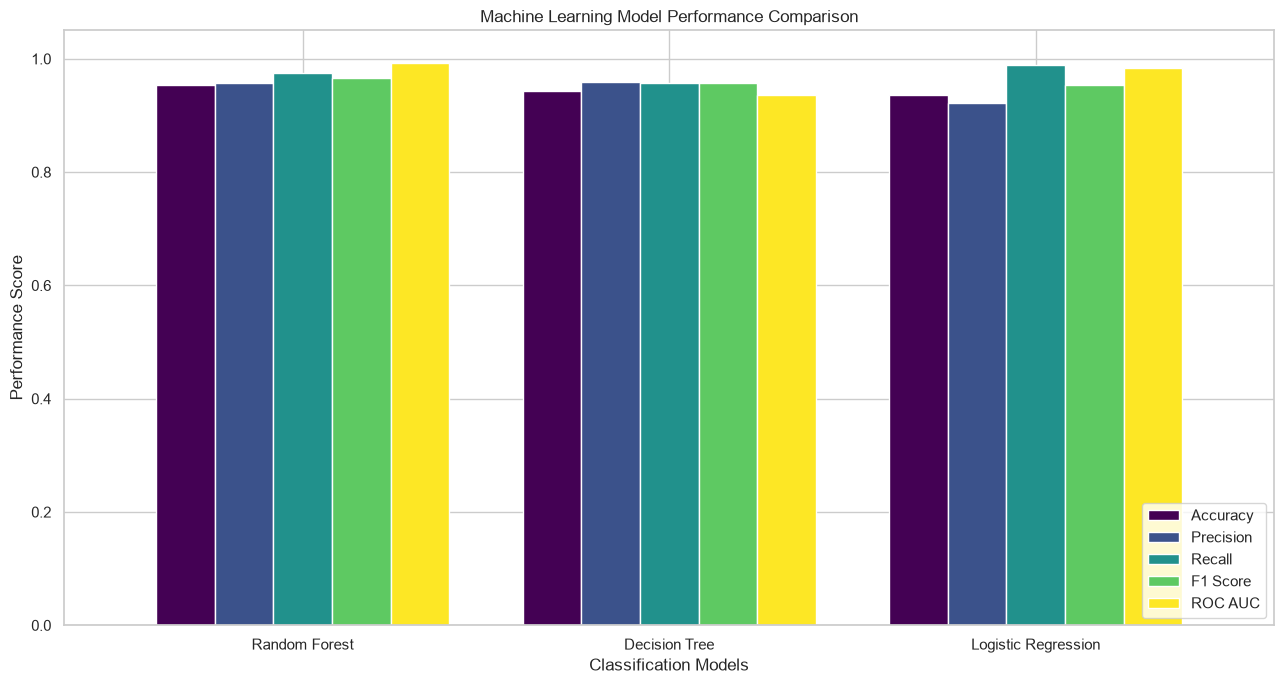

In [10]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

performance_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8,
    colormap="viridis"
)

plt.title("Machine Learning Model Performance Comparison")

plt.xlabel("Classification Models")
plt.ylabel("Performance Score")

plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "model_comparison.png",
    dpi=300
)

plt.show()

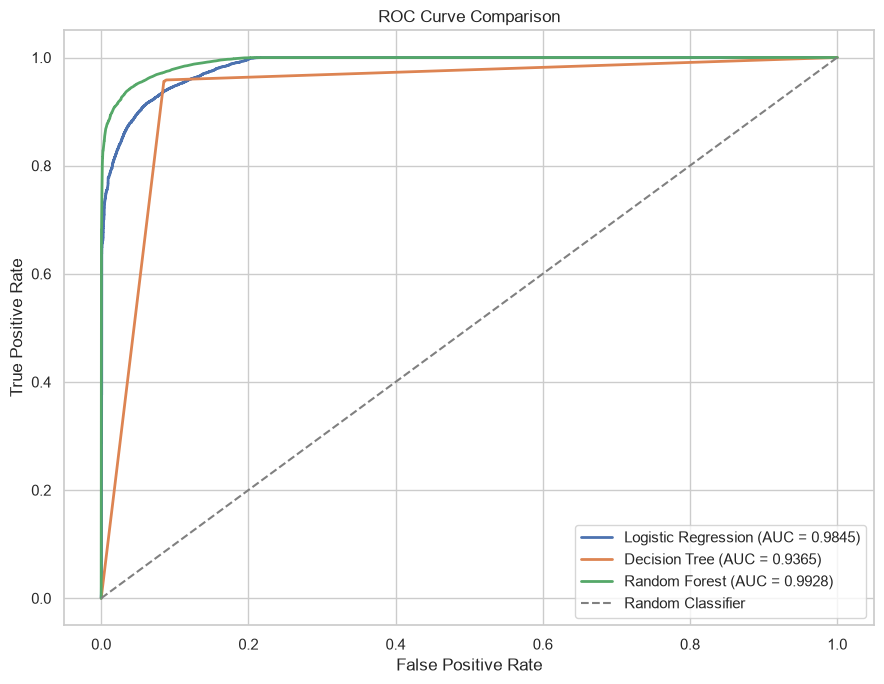

In [11]:
plt.figure(figsize=(9, 7))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_val,
        y_prob
    )

    auc_score = roc_auc_score(
        y_val,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "roc_curve_comparison.png",
    dpi=300
)

plt.show()

,Model,False Positive,False Negative,False Positive Rate,False Negative Rate
0,Random Forest,1042,580,0.0930,0.0243
1,Decision Tree,966,1039,0.0862,0.0435
2,Logistic Regression,2000,272,0.1786,0.0114


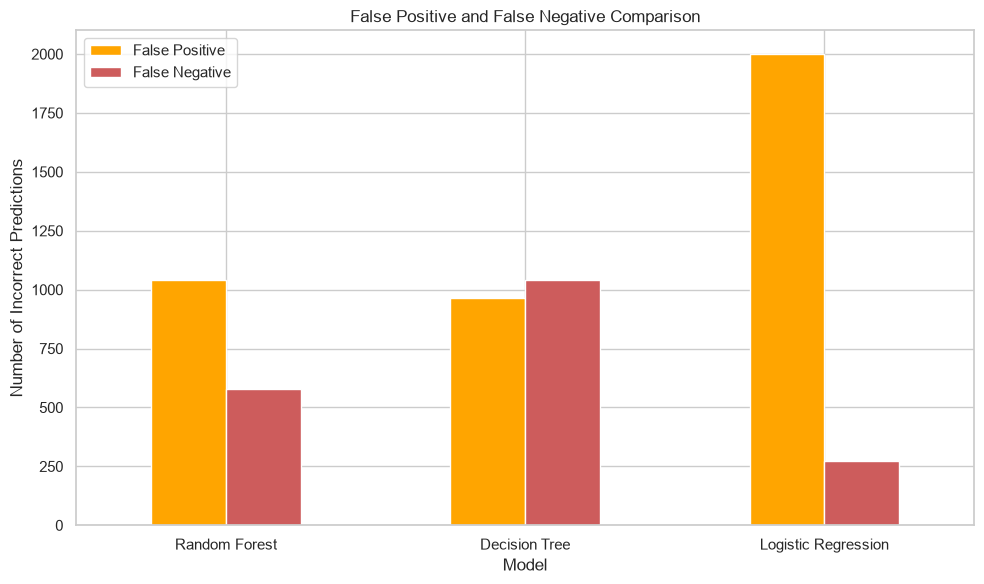

In [13]:
error_analysis = performance_df[[
    "Model",
    "False Positive",
    "False Negative",
    "False Positive Rate",
    "False Negative Rate"
]]

display(error_analysis.round(4))

error_analysis.set_index("Model")[[
    "False Positive",
    "False Negative"
]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["orange", "indianred"]
)

plt.title("False Positive and False Negative Comparison")

plt.xlabel("Model")
plt.ylabel("Number of Incorrect Predictions")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "error_comparison.png",
    dpi=300
)

plt.show()

In [14]:
best_accuracy = performance_df.loc[
    performance_df["Accuracy"].idxmax()
]

best_recall = performance_df.loc[
    performance_df["Recall"].idxmax()
]

best_f1 = performance_df.loc[
    performance_df["F1 Score"].idxmax()
]

lowest_fn = performance_df.loc[
    performance_df["False Negative"].idxmin()
]

print("Highest Accuracy:",
      best_accuracy["Model"])

print("Highest Recall:",
      best_recall["Model"])

print("Highest F1 Score:",
      best_f1["Model"])

print("Lowest False Negatives:",
      lowest_fn["Model"])

Highest Accuracy: Random Forest
Highest Recall: Logistic Regression
Highest F1 Score: Random Forest
Lowest False Negatives: Logistic Regression


In [15]:
training_summary = pd.read_csv(
    RESULT_DIR / "training_summary.csv"
)

time_comparison = training_summary.merge(
    performance_df[[
        "Model",
        "Prediction Time (Seconds)"
    ]],
    on="Model"
)

display(time_comparison.round(4))

,Model,Training Time (Seconds),Status,Prediction Time (Seconds)
0,Logistic Regression,13.32,Successfully Trained,0.2882
1,Decision Tree,19.54,Successfully Trained,0.0998
2,Random Forest,137.91,Successfully Trained,0.3884


In [16]:
performance_df.to_csv(
    RESULT_DIR / "model_performance.csv",
    index=False
)

error_analysis.to_csv(
    RESULT_DIR / "error_analysis.csv",
    index=False
)

all_reports = pd.concat(
    classification_reports
)

all_reports.index.name = "Class / Metric"

all_reports.to_csv(
    RESULT_DIR / "classification_report.csv"
)

time_comparison.to_csv(
    RESULT_DIR / "time_comparison.csv",
    index=False
)

print("All evaluation reports saved successfully!")

All evaluation reports saved successfully!
